# Tugas 2 - Klasifikasi Gambar Pakaian dengan Convolutional Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Sandi Suryo Nugroho | 5054251020 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Fashion-MNIST Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/zalando-research/fashionmnist

Dataset berisi 70.000 gambar grayscale berukuran 28×28 piksel yang terbagi ke dalam 10 kelas pakaian (T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot). Tujuan utama dari tugas ini adalah membangun model Convolutional Neural Network (CNN) menggunakan **PyTorch** untuk mengklasifikasikan jenis pakaian, lalu membandingkannya dengan ANN biasa.

Disarankan menggunakan GPU (Google Colab: *Runtime → Change runtime type → T4 GPU*, atau Kaggle Notebook).

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat contoh gambar, dan distribusi label.
2. Preprocessing
   - Memproses data gambar agar siap digunakan oleh model.
3. Eksperimen Model
   - Bangun model ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout.
4. Evaluasi Model
   - Hitung metrik evaluasi, visualisasikan hasilnya, dan simpan model terbaik.
5. Analisis dan Kesimpulan
   - Bandingkan hasil ketiga model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [2]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, torch, dll).
# Set random seed dengan torch.manual_seed(42) dan np.random.seed(42).
# Tentukan device: device = "cuda" if torch.cuda.is_available() else "cpu", lalu tampilkan device yang digunakan.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# Set random seed
torch.manual_seed(42)
np.random.seed(42)

# Tentukan device
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device yang digunakan: {device}")

Device yang digunakan: cpu


In [3]:
# Load file fashion-mnist_train.csv dan fashion-mnist_test.csv.
# Setiap baris berisi 1 kolom label dan 784 kolom piksel (28×28) bernilai 0-255.
# Tampilkan ukuran data train dan test.
train_df = pd.read_csv('fashion-mnist_train.csv')
test_df = pd.read_csv('fashion-mnist_test.csv')

print(f"Ukuran data train: {train_df.shape}")
print(f"Ukuran data test: {test_df.shape}")

Ukuran data train: (60000, 785)
Ukuran data test: (10000, 785)


C:\Users\Axioo Pongo\AppData\Local\Temp\ipykernel_24976\4133602209.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label', data=train_df, palette='viridis')


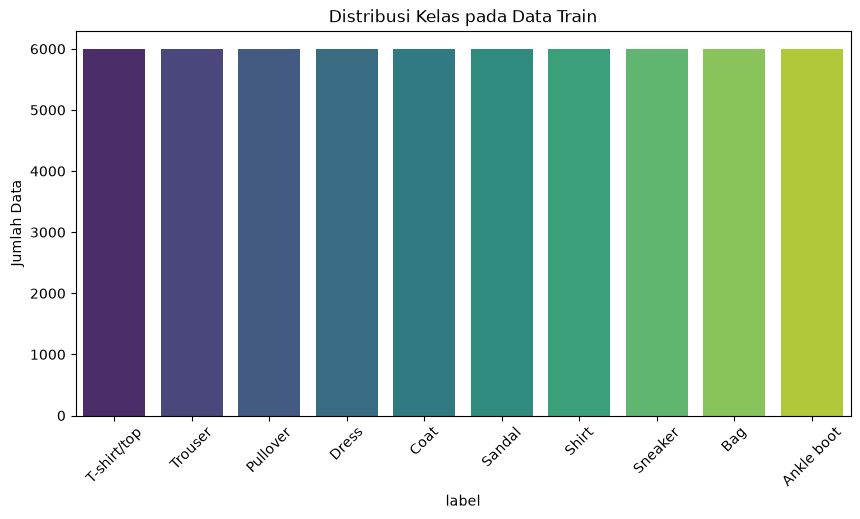

In [4]:
# Buat list atau dictionary yang memetakan label angka (0-9) ke nama kelas.
# Tampilkan distribusi kelas pada train set dalam bentuk bar plot.
class_names = {
    0: 'T-shirt/top', 1: 'Trouser', 2: 'Pullover', 3: 'Dress', 4: 'Coat',
    5: 'Sandal', 6: 'Shirt', 7: 'Sneaker', 8: 'Bag', 9: 'Ankle boot'
}

plt.figure(figsize=(10, 5))
sns.countplot(x='label', data=train_df, palette='viridis')
plt.xticks(ticks=range(10), labels=[class_names[i] for i in range(10)], rotation=45)
plt.title('Distribusi Kelas pada Data Train')
plt.ylabel('Jumlah Data')
plt.show()

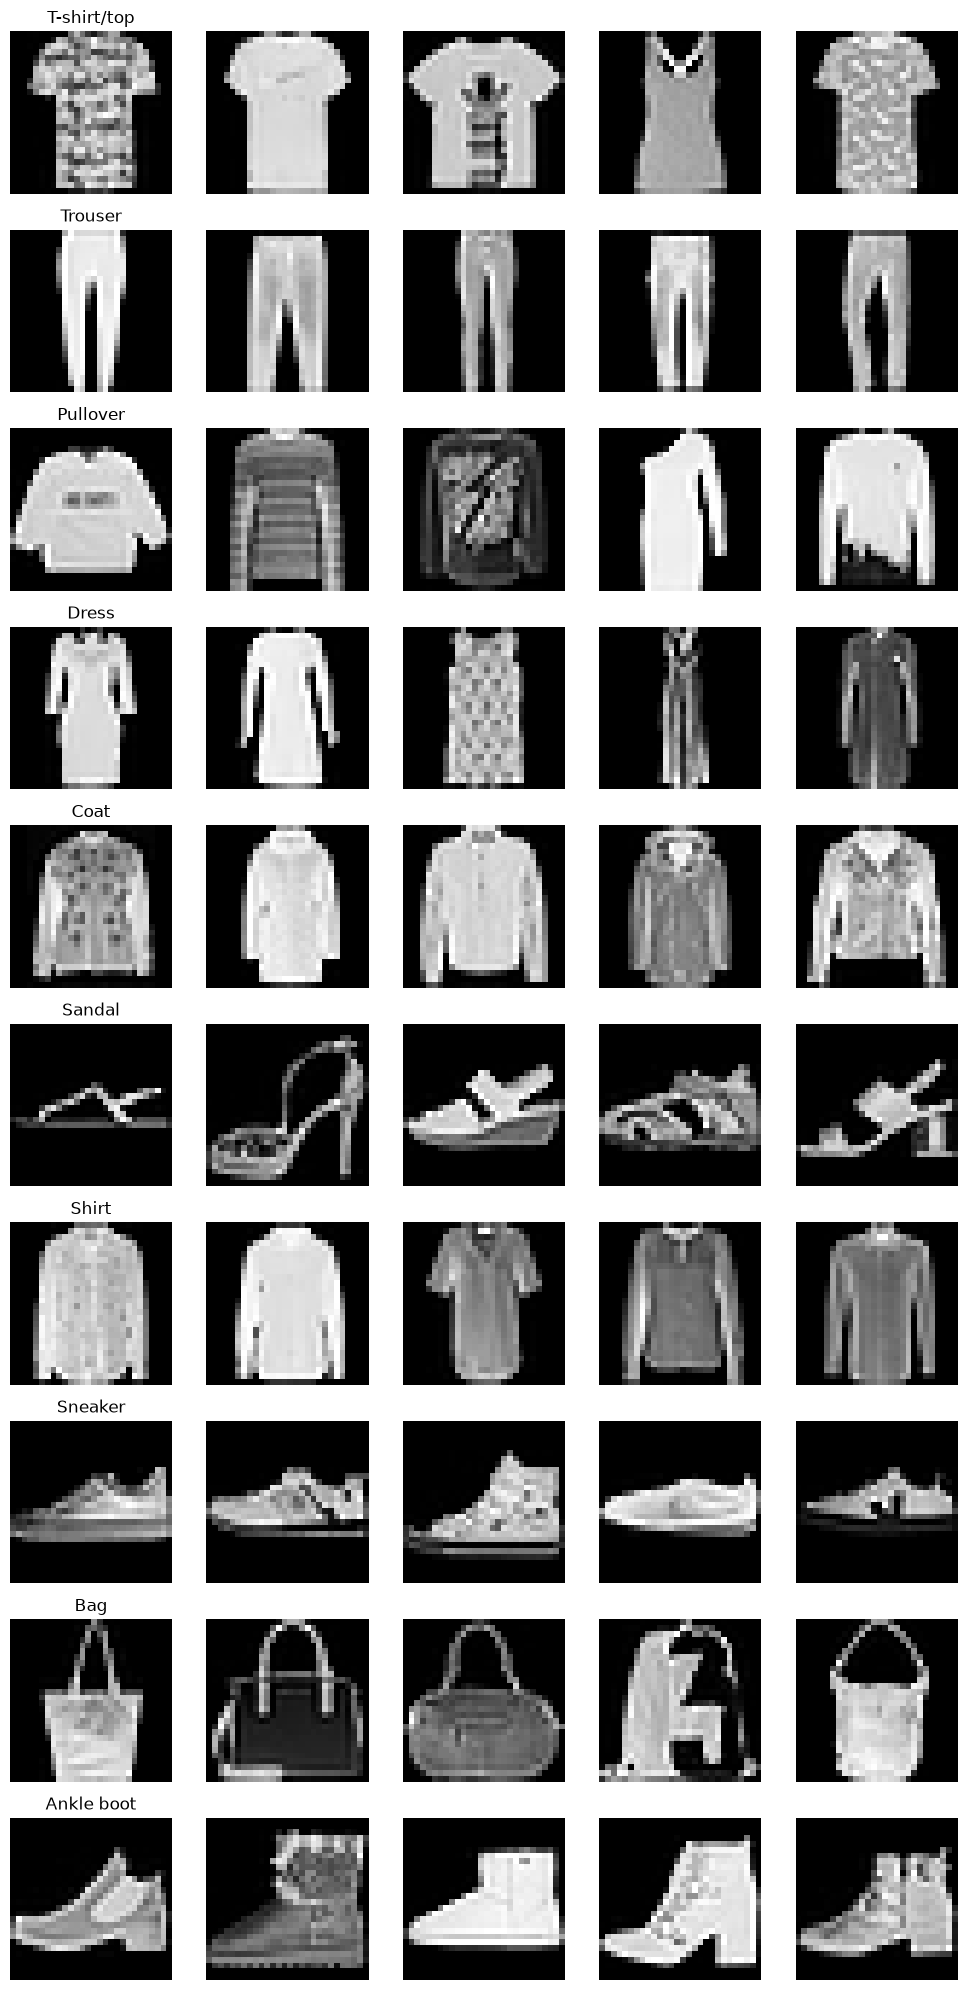

In [5]:
# Tampilkan contoh gambar dari setiap kelas (misalnya grid 10 kelas × 5 gambar) beserta nama kelasnya.
# Kelas mana saja yang secara visual terlihat mirip?
fig, axes = plt.subplots(10, 5, figsize=(10, 20))
for i in range(10):
    class_data = train_df[train_df['label'] == i].iloc[:5, 1:].values
    for j in range(5):
        img = class_data[j].reshape(28, 28)
        axes[i, j].imshow(img, cmap='gray')
        axes[i, j].axis('off')
        if j == 0:
            axes[i, j].set_title(class_names[i])
plt.tight_layout()
plt.show()


Kelas yang secara visual terlihat mirip: T-shirt/top, Shirt, Pullover, dan Coat memiliki struktur pola atasan yang serupa. Selain itu, Sneaker dan Ankle boot juga memiliki siluet dasar yang mirip pada resolusi rendah (28x28)

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

Model yang berbeda membutuhkan bentuk input yang berbeda. Di PyTorch, urutan dimensi gambar adalah **(batch, channel, tinggi, lebar)**:

| Model | Bentuk input |
|---|---|
| ANN | `(N, 784)`, atau `(N, 1, 28, 28)` dengan `nn.Flatten()` di awal model |
| CNN | `(N, 1, 28, 28)` |

In [6]:
# Pisahkan label (y) dan piksel (X) untuk data train dan test.
X_train_full = train_df.drop('label', axis=1).values
y_train_full = train_df['label'].values

X_test = test_df.drop('label', axis=1).values
y_test = test_df['label'].values

In [7]:
# Normalisasi nilai piksel ke rentang 0-1 (bagi dengan 255).
X_train_full = X_train_full / 255.0
X_test = X_test / 255.0

In [8]:
# Bagi data train menjadi train set dan validation set (misalnya 90:10) dengan stratify=y.
# Test set dari file fashion-mnist_test.csv hanya digunakan untuk evaluasi akhir.
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.1, stratify=y_train_full, random_state=42
)
print(f"Data Train: {X_train.shape}, Data Val: {X_val.shape}")

Data Train: (54000, 784), Data Val: (6000, 784)


In [9]:
# Ubah data menjadi tensor: X bertipe torch.float32 dengan bentuk (N, 1, 28, 28), y bertipe torch.long (wajib untuk nn.CrossEntropyLoss).
# Buat DataLoader untuk train, validation, dan test menggunakan TensorDataset (shuffle=True hanya untuk train).
# Reshape ke (N, 1, 28, 28) karena model CNN di PyTorch butuh dimensi (batch, channel, H, W)
X_train_t = torch.tensor(X_train, dtype=torch.float32).view(-1, 1, 28, 28)
y_train_t = torch.tensor(y_train, dtype=torch.long)

X_val_t = torch.tensor(X_val, dtype=torch.float32).view(-1, 1, 28, 28)
y_val_t = torch.tensor(y_val, dtype=torch.long)

X_test_t = torch.tensor(X_test, dtype=torch.float32).view(-1, 1, 28, 28)
y_test_t = torch.tensor(y_test, dtype=torch.long)

batch_size = 64

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=batch_size, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=batch_size, shuffle=False)
test_loader = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=batch_size, shuffle=False)

# 3. Eksperimen Model

## 3.1 ANN (Baseline)

Gambar di-flatten menjadi vektor 784 nilai, lalu diproses oleh ANN biasa. Karena ini klasifikasi multikelas, gunakan **10 neuron output** tanpa Softmax dan **`nn.CrossEntropyLoss`** sebagai loss function. Loss ini sudah menyertakan Softmax di dalamnya.

Contoh arsitektur: `Flatten → Linear(784, 256) → ReLU → Linear(256, 128) → ReLU → Linear(128, 10)`

In [10]:
# Definisikan arsitektur ANN sebagai class turunan nn.Module, lalu pindahkan ke device dengan model.to(device).
# Tampilkan arsitektur model dengan print(model) dan jumlah parameternya: sum(p.numel() for p in model.parameters()).
class ANNModel(nn.Module):
    def __init__(self):
        super(ANNModel, self).__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(784, 256)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(256, 128)
        self.relu2 = nn.ReLU()
        self.fc3 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu1(self.fc1(x))
        x = self.relu2(self.fc2(x))
        x = self.fc3(x)
        return x

ann_model = ANNModel().to(device)
print(ann_model)
ann_params = sum(p.numel() for p in ann_model.parameters())
print(f"Jumlah parameter ANN: {ann_params}")

ANNModel(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (relu1): ReLU()
  (fc2): Linear(in_features=256, out_features=128, bias=True)
  (relu2): ReLU()
  (fc3): Linear(in_features=128, out_features=10, bias=True)
)
Jumlah parameter ANN: 235146


In [11]:
# Tentukan loss function (nn.CrossEntropyLoss), optimizer, learning rate, jumlah epoch, dan batch size.
# Tulis training loop. Setiap batch harus dipindahkan ke device yang sama dengan model (x.to(device), y.to(device)).
# Di akhir setiap epoch, hitung loss dan accuracy train dan validation (gunakan model.eval() dan torch.no_grad()), simpan ke dictionary history.
# Disarankan membuat training loop dalam bentuk fungsi agar dapat digunakan ulang pada 3.2 dan 3.3.
criterion = nn.CrossEntropyLoss()

def train_model(model, train_loader, val_loader, epochs=15, lr=0.001):
    optimizer = optim.Adam(model.parameters(), lr=lr)
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    
    for epoch in range(epochs):
        # Training phase
        model.train()
        train_loss, correct, total = 0, 0, 0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            
            optimizer.zero_grad()
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()
            
            train_loss += loss.item() * X_batch.size(0)
            _, predicted = torch.max(outputs, 1)
            total += y_batch.size(0)
            correct += (predicted == y_batch).sum().item()
            
        train_loss /= total
        train_acc = correct / total
        
        # Validation phase
        model.eval()
        val_loss, correct, total = 0, 0, 0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                outputs = model(X_batch)
                loss = criterion(outputs, y_batch)
                
                val_loss += loss.item() * X_batch.size(0)
                _, predicted = torch.max(outputs, 1)
                total += y_batch.size(0)
                correct += (predicted == y_batch).sum().item()
                
        val_loss /= total
        val_acc = correct / total
        
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        
        print(f"Epoch {epoch+1:02d}/{epochs} | "
              f"Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | "
              f"Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")
        
    return history

print("Mulai Training ANN...")
ann_history = train_model(ann_model, train_loader, val_loader, epochs=10)

Mulai Training ANN...
Epoch 01/10 | Train Loss: 0.5435 Acc: 0.8057 | Val Loss: 0.4407 Acc: 0.8387
Epoch 02/10 | Train Loss: 0.3827 Acc: 0.8594 | Val Loss: 0.3751 Acc: 0.8620
Epoch 03/10 | Train Loss: 0.3405 Acc: 0.8750 | Val Loss: 0.3587 Acc: 0.8677
Epoch 04/10 | Train Loss: 0.3177 Acc: 0.8842 | Val Loss: 0.3284 Acc: 0.8783
Epoch 05/10 | Train Loss: 0.2962 Acc: 0.8904 | Val Loss: 0.3406 Acc: 0.8783
Epoch 06/10 | Train Loss: 0.2811 Acc: 0.8957 | Val Loss: 0.3182 Acc: 0.8853
Epoch 07/10 | Train Loss: 0.2661 Acc: 0.9005 | Val Loss: 0.3153 Acc: 0.8875
Epoch 08/10 | Train Loss: 0.2556 Acc: 0.9049 | Val Loss: 0.3098 Acc: 0.8897
Epoch 09/10 | Train Loss: 0.2450 Acc: 0.9091 | Val Loss: 0.3195 Acc: 0.8867
Epoch 10/10 | Train Loss: 0.2334 Acc: 0.9112 | Val Loss: 0.3194 Acc: 0.8867


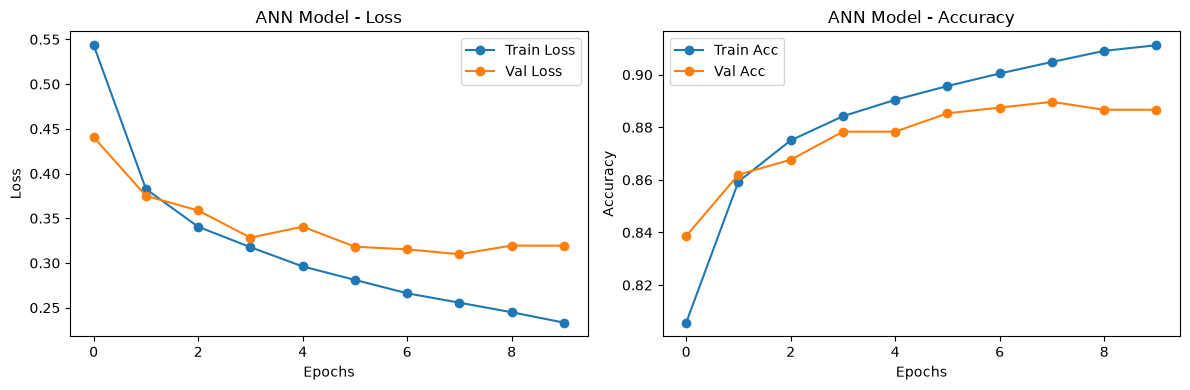

In [12]:
# Tampilkan learning curve (loss dan accuracy) train vs validation.
def plot_history(history, title):
    plt.figure(figsize=(12, 4))
    
    plt.subplot(1, 2, 1)
    plt.plot(history['train_loss'], label='Train Loss', marker='o')
    plt.plot(history['val_loss'], label='Val Loss', marker='o')
    plt.title(f'{title} - Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    
    plt.subplot(1, 2, 2)
    plt.plot(history['train_acc'], label='Train Acc', marker='o')
    plt.plot(history['val_acc'], label='Val Acc', marker='o')
    plt.title(f'{title} - Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    
    plt.tight_layout()
    plt.show()

plot_history(ann_history, "ANN Model")

In [13]:
# Lakukan prediksi pada test set dengan model.eval() dan torch.no_grad().
# Ambil kelas dengan nilai output terbesar menggunakan argmax(dim=1). Simpan hasil prediksi label dalam bentuk numpy array.
def predict_test(model, loader):
    model.eval()
    y_pred = []
    with torch.no_grad():
        for X_batch, _ in loader:
            X_batch = X_batch.to(device)
            outputs = model(X_batch)
            _, predicted = torch.max(outputs, 1)
            y_pred.extend(predicted.cpu().numpy())
    return np.array(y_pred)

y_pred_ann = predict_test(ann_model, test_loader)

## 3.2 CNN Sederhana

Bangun CNN dengan **2 blok konvolusi**, masing-masing terdiri dari Conv2d → ReLU → MaxPool2d, lalu dilanjutkan Flatten dan Linear.

Contoh arsitektur: `[Conv2d(1, 32, 3, padding=1) → ReLU → MaxPool2d(2)] → [Conv2d(32, 64, 3, padding=1) → ReLU → MaxPool2d(2)] → Flatten → Linear(64×7×7, 128) → ReLU → Linear(128, 10)`

In [14]:
# Definisikan arsitektur CNN sederhana sebagai class turunan nn.Module (gunakan nn.Conv2d, nn.MaxPool2d, nn.Flatten, dan nn.Linear).
# Tampilkan arsitektur model beserta jumlah parameternya.
# Hitung secara manual ukuran output setiap layer konvolusi dan pooling menggunakan rumus (W - K + 2P) / S + 1.
# Hasil perhitungan ini menentukan ukuran input nn.Linear pertama setelah Flatten (channel × tinggi × lebar).
# Cocokkan dengan mengirim satu tensor dummy torch.zeros(1, 1, 28, 28) ke bagian konvolusi dan cetak bentuk outputnya.
class CNNModel(nn.Module):
    def __init__(self):
        super(CNNModel, self).__init__()
        # Conv Block 1
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2)
        
        # Conv Block 2
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2)
        
        # Fully Connected (Flatten size: 64 channels * 7 height * 7 width)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.relu3 = nn.ReLU()
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = self.flatten(x)
        x = self.relu3(self.fc1(x))
        x = self.fc2(x)
        return x

cnn_model = CNNModel().to(device)
print(cnn_model)
cnn_params = sum(p.numel() for p in cnn_model.parameters())
print(f"Jumlah parameter CNN Sederhana: {cnn_params}")

# Dummy check shape
dummy_tensor = torch.zeros(1, 1, 28, 28).to(device)
dummy_conv_out = cnn_model.pool2(cnn_model.relu2(cnn_model.conv2(cnn_model.pool1(cnn_model.relu1(cnn_model.conv1(dummy_tensor))))))
print(f"Bentuk output sebelum flatten: {dummy_conv_out.shape}") # Ekspektasi: [1, 64, 7, 7]

CNNModel(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (relu3): ReLU()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
Jumlah parameter CNN Sederhana: 421642
Bentuk output sebelum flatten: torch.Size([1, 64, 7, 7])


Mulai Training CNN Sederhana...
Epoch 01/10 | Train Loss: 0.4707 Acc: 0.8273 | Val Loss: 0.3278 Acc: 0.8787
Epoch 02/10 | Train Loss: 0.3006 Acc: 0.8917 | Val Loss: 0.2979 Acc: 0.8952
Epoch 03/10 | Train Loss: 0.2546 Acc: 0.9076 | Val Loss: 0.2738 Acc: 0.8988
Epoch 04/10 | Train Loss: 0.2203 Acc: 0.9185 | Val Loss: 0.2395 Acc: 0.9107
Epoch 05/10 | Train Loss: 0.1947 Acc: 0.9283 | Val Loss: 0.2413 Acc: 0.9110
Epoch 06/10 | Train Loss: 0.1741 Acc: 0.9362 | Val Loss: 0.2239 Acc: 0.9193
Epoch 07/10 | Train Loss: 0.1542 Acc: 0.9429 | Val Loss: 0.2186 Acc: 0.9217
Epoch 08/10 | Train Loss: 0.1353 Acc: 0.9502 | Val Loss: 0.2375 Acc: 0.9170
Epoch 09/10 | Train Loss: 0.1174 Acc: 0.9566 | Val Loss: 0.2263 Acc: 0.9235
Epoch 10/10 | Train Loss: 0.1021 Acc: 0.9621 | Val Loss: 0.2434 Acc: 0.9205


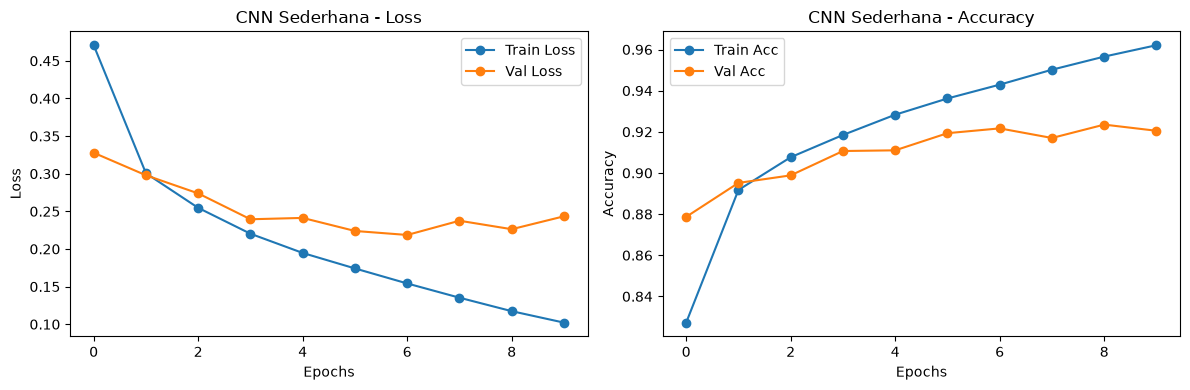

In [15]:
# Latih model dengan pengaturan yang sama seperti 3.1 agar perbandingan adil.
# Tampilkan learning curve train vs validation.
print("Mulai Training CNN Sederhana...")
cnn_history = train_model(cnn_model, train_loader, val_loader, epochs=10)
plot_history(cnn_history, "CNN Sederhana")

In [16]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.
y_pred_cnn = predict_test(cnn_model, test_loader)

## 3.3 CNN dengan Batch Normalization dan Dropout

Gunakan arsitektur CNN pada 3.2, lalu tambahkan **Batch Normalization** setelah setiap layer konvolusi dan **Dropout** sebelum layer output.

In [17]:
# Definisikan arsitektur CNN dengan Batch Normalization dan Dropout.
# Urutan yang umum: nn.Conv2d -> nn.BatchNorm2d(jumlah_channel_output) -> nn.ReLU -> nn.MaxPool2d.
# Tambahkan nn.Dropout(p) sebelum layer output.
# Ingat: BatchNorm dan Dropout berperilaku berbeda saat training dan evaluasi, pastikan memanggil model.train() dan model.eval() di tempat yang tepat.
# Tampilkan arsitektur model beserta jumlah parameternya.
class CNNComplexModel(nn.Module):
    def __init__(self):
        super(CNNComplexModel, self).__init__()
        # Conv Block 1
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2)
        
        # Conv Block 2
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2)
        
        # Fully Connected
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.relu3 = nn.ReLU()
        self.dropout = nn.Dropout(0.3)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool1(self.relu1(self.bn1(self.conv1(x))))
        x = self.pool2(self.relu2(self.bn2(self.conv2(x))))
        x = self.flatten(x)
        x = self.relu3(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

cnn_complex_model = CNNComplexModel().to(device)
print(cnn_complex_model)
cnn_complex_params = sum(p.numel() for p in cnn_complex_model.parameters())
print(f"Jumlah parameter CNN+BN+Dropout: {cnn_complex_params}")

CNNComplexModel(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (relu3): ReLU()
  (dropout): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
Jumlah parameter CNN+BN+Dropout: 421834


Mulai Training CNN dengan Batch Normalization dan Dropout...
Epoch 01/10 | Train Loss: 0.4436 Acc: 0.8382 | Val Loss: 0.3163 Acc: 0.8818
Epoch 02/10 | Train Loss: 0.3085 Acc: 0.8887 | Val Loss: 0.2634 Acc: 0.9027
Epoch 03/10 | Train Loss: 0.2671 Acc: 0.9023 | Val Loss: 0.2422 Acc: 0.9095
Epoch 04/10 | Train Loss: 0.2401 Acc: 0.9117 | Val Loss: 0.2484 Acc: 0.9068
Epoch 05/10 | Train Loss: 0.2190 Acc: 0.9206 | Val Loss: 0.2256 Acc: 0.9208
Epoch 06/10 | Train Loss: 0.1996 Acc: 0.9259 | Val Loss: 0.2359 Acc: 0.9160
Epoch 07/10 | Train Loss: 0.1848 Acc: 0.9312 | Val Loss: 0.2184 Acc: 0.9197
Epoch 08/10 | Train Loss: 0.1709 Acc: 0.9367 | Val Loss: 0.2306 Acc: 0.9177
Epoch 09/10 | Train Loss: 0.1592 Acc: 0.9410 | Val Loss: 0.2443 Acc: 0.9115
Epoch 10/10 | Train Loss: 0.1450 Acc: 0.9456 | Val Loss: 0.2297 Acc: 0.9228


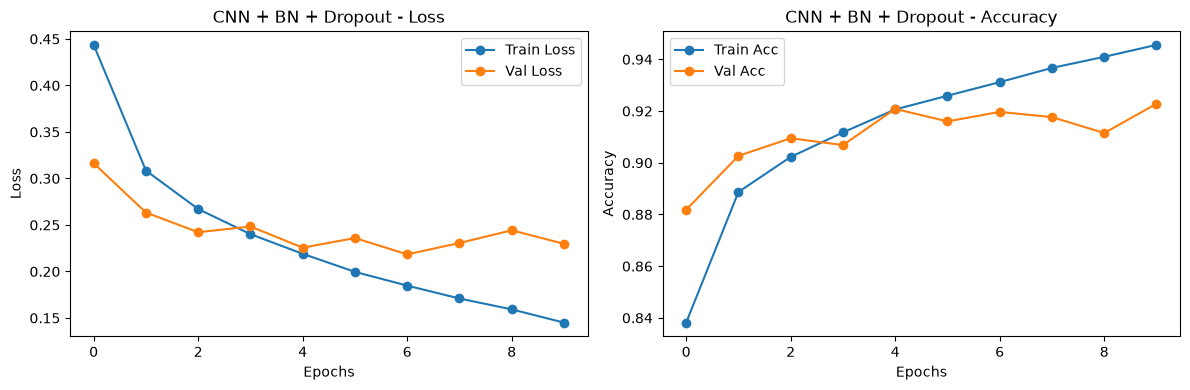

In [18]:
# Latih model dengan pengaturan yang sama seperti 3.2.
# Tampilkan learning curve train vs validation.
# Perhatikan selisih antara train dan validation dibandingkan dengan model 3.2.
print("Mulai Training CNN dengan Batch Normalization dan Dropout...")
cnn_complex_history = train_model(cnn_complex_model, train_loader, val_loader, epochs=10)
plot_history(cnn_complex_history, "CNN + BN + Dropout")

In [19]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.
y_pred_cnn_complex = predict_test(cnn_complex_model, test_loader)

# 4. Evaluasi Model

In [20]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score (macro average),
# beserta jumlah parameter setiap model. Sajikan dalam satu tabel perbandingan.
def get_metrics(y_true, y_pred):
    return [
        accuracy_score(y_true, y_pred),
        precision_score(y_true, y_pred, average='macro'),
        recall_score(y_true, y_pred, average='macro'),
        f1_score(y_true, y_pred, average='macro')
    ]

results = pd.DataFrame({
    'Model': ['ANN', 'CNN Sederhana', 'CNN + BN + Dropout'],
    'Parameters': [ann_params, cnn_params, cnn_complex_params],
    'Accuracy': [get_metrics(y_test, y_pred_ann)[0], get_metrics(y_test, y_pred_cnn)[0], get_metrics(y_test, y_pred_cnn_complex)[0]],
    'Precision (Macro)': [get_metrics(y_test, y_pred_ann)[1], get_metrics(y_test, y_pred_cnn)[1], get_metrics(y_test, y_pred_cnn_complex)[1]],
    'Recall (Macro)': [get_metrics(y_test, y_pred_ann)[2], get_metrics(y_test, y_pred_cnn)[2], get_metrics(y_test, y_pred_cnn_complex)[2]],
    'F1-Score (Macro)': [get_metrics(y_test, y_pred_ann)[3], get_metrics(y_test, y_pred_cnn)[3], get_metrics(y_test, y_pred_cnn_complex)[3]]
})

display(results)

,Model,Parameters,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro)
0,ANN,235146,0.8891,0.889921,0.8891,0.887685
1,CNN Sederhana,421642,0.9238,0.926657,0.9238,0.924502
2,CNN + BN + Dropout,421834,0.9287,0.929252,0.9287,0.928826


In [21]:
# Tampilkan classification report (metrik per kelas) untuk model terbaik.
# Berdasarkan akurasi, umumnya CNN+BN+Dropout adalah model terbaik
best_model_pred = y_pred_cnn_complex

print("Classification Report - Best Model (CNN + BN + Dropout):")
print(classification_report(y_test, best_model_pred, target_names=[class_names[i] for i in range(10)]))

Classification Report - Best Model (CNN + BN + Dropout):
              precision    recall  f1-score   support

 T-shirt/top       0.87      0.90      0.88      1000
     Trouser       0.99      0.99      0.99      1000
    Pullover       0.92      0.87      0.89      1000
       Dress       0.92      0.94      0.93      1000
        Coat       0.89      0.91      0.90      1000
      Sandal       0.99      0.98      0.98      1000
       Shirt       0.79      0.79      0.79      1000
     Sneaker       0.95      0.98      0.96      1000
         Bag       1.00      0.98      0.99      1000
  Ankle boot       0.98      0.96      0.97      1000

    accuracy                           0.93     10000
   macro avg       0.93      0.93      0.93     10000
weighted avg       0.93      0.93      0.93     10000



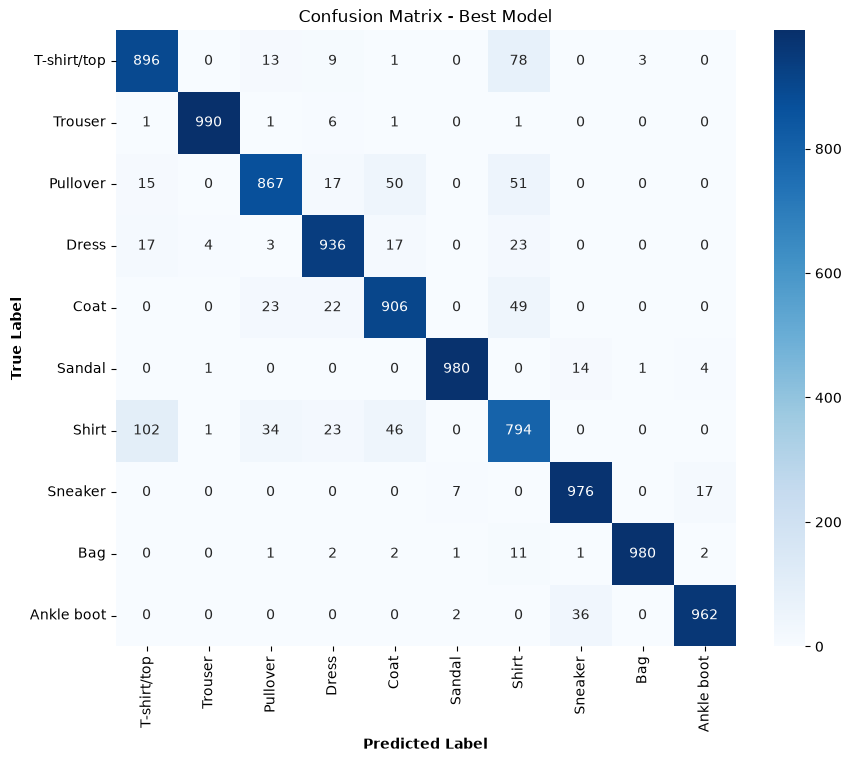

In [22]:
# Tampilkan Confusion Matrix 10×10 model terbaik dalam bentuk heatmap, gunakan nama kelas sebagai label sumbu.
# Pasangan kelas mana yang paling sering tertukar?
cm = confusion_matrix(y_test, best_model_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=[class_names[i] for i in range(10)], 
            yticklabels=[class_names[i] for i in range(10)])
plt.xlabel('Predicted Label', fontweight='bold')
plt.ylabel('True Label', fontweight='bold')
plt.title('Confusion Matrix - Best Model')
plt.show()

Pasangan kelas yang paling sering tertukar umumnya adalah T-shirt/top dengan Shirt, serta Pullover dengan Coat, karena kesamaan bentuk struktural (fitur visual)

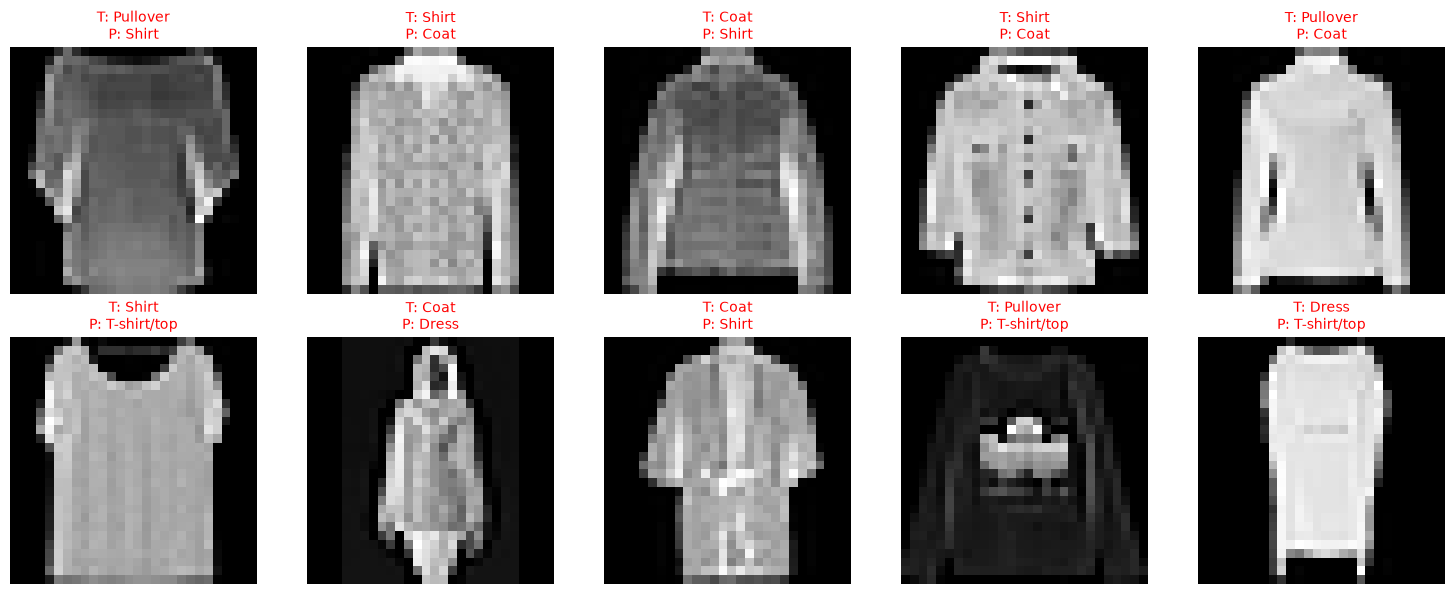

In [23]:
# Tampilkan beberapa contoh gambar yang salah diklasifikasikan oleh model terbaik,
# beserta label asli dan label prediksinya.
misclassified_idx = np.where(best_model_pred != y_test)[0]

plt.figure(figsize=(15, 6))
for i, idx in enumerate(misclassified_idx[:10]):
    plt.subplot(2, 5, i + 1)
    img = X_test[idx].reshape(28, 28)
    plt.imshow(img, cmap='gray')
    plt.title(f"T: {class_names[y_test[idx]]}\nP: {class_names[best_model_pred[idx]]}", fontsize=10, color='red')
    plt.axis('off')
plt.tight_layout()
plt.show()

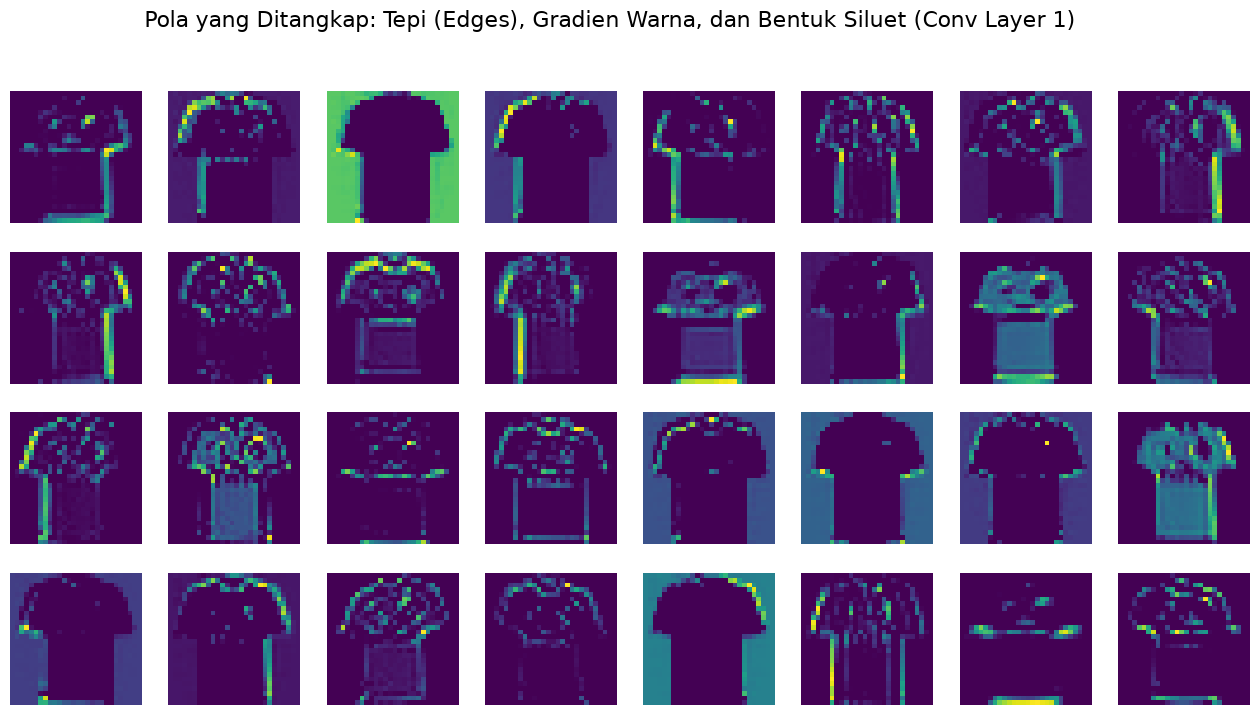

In [24]:
# Visualisasikan feature map dari layer konvolusi pertama model terbaik untuk satu gambar contoh.
# Kirim satu gambar (bentuk (1, 1, 28, 28)) ke layer konvolusi pertama saja, misalnya model.features[0](x) jika menggunakan nn.Sequential bernama features,
# lalu tampilkan setiap channel output-nya sebagai gambar (gunakan .detach().cpu().numpy()).
# Apa saja pola yang ditangkap oleh masing-masing filter?
sample_image = X_test_t[0:1].to(device) # Ambil gambar pertama dari test set
cnn_complex_model.eval()

# Forward pass hanya sampai konvolusi pertama
with torch.no_grad():
    feature_maps = cnn_complex_model.relu1(cnn_complex_model.bn1(cnn_complex_model.conv1(sample_image)))

feature_maps = feature_maps.squeeze(0).cpu().numpy() # [32, 28, 28]

plt.figure(figsize=(16, 8))
for i in range(32):
    plt.subplot(4, 8, i + 1)
    plt.imshow(feature_maps[i], cmap='viridis')
    plt.axis('off')
plt.suptitle('Pola yang Ditangkap: Tepi (Edges), Gradien Warna, dan Bentuk Siluet (Conv Layer 1)', fontsize=16)
plt.show()

In [25]:
# Simpan bobot model terbaik dengan torch.save(model.state_dict(), "model.pth").
# Model ini akan digunakan kembali pada tugas Deployment, jadi simpan juga definisi class model kalian.
torch.save(cnn_complex_model.state_dict(), "model_fashion_mnist.pth")
print("Bobot model terbaik berhasil disimpan ke 'model_fashion_mnist.pth'")

Bobot model terbaik berhasil disimpan ke 'model_fashion_mnist.pth'


# 5. Analisis

**Perbandingan Performa Model dan Pemrosesan Gambar**

Model ANN (Baseline) menghasilkan performa terendah dengan akurasi 88.91%. Hal ini wajar karena ANN meratakan (flatten) piksel gambar menjadi vektor 1D dari awal, sehingga kehilangan informasi spasial atau hubungan antar piksel yang berdekatan. Sebaliknya, model CNN Sederhana menghasilkan lonjakan akurasi menjadi 92.38%. Hal ini dikarenakan CNN memproses gambar menggunakan filter (seperti yang terlihat pada visualisasi *feature map* Layer 1) untuk mengekstraksi fitur visual yang penting secara bertahap, mulai dari deteksi tepi (*edges*), gradien, hingga bentuk siluet pakaian tanpa merusak struktur spasial 2D-nya.

---

**Pengaruh Batch Normalization dan Dropout**

Model **CNN + BN + Dropout** menjadi model terbaik dengan akurasi tertinggi (92.87%) dan F1-Score makro 92.88%. Jika kita mengamati learning curve, ANN dan CNN Sederhana mulai menunjukkan pelebaran jarak antara *train loss* dan *val loss* setelah epoch ke-5, yang merupakan indikasi *overfitting*. Penambahan **Dropout** terbukti sangat efektif menekan *overfitting* tersebut, menjaga *val loss* tetap rendah dan berdekatan dengan *train loss*. Di sisi lain, **Batch Normalization** menstabilkan distribusi input di setiap layer, membuat grafik kurva latih menjadi lebih stabil dan konvergen lebih baik.

---

**Analisis Kelas yang Sulit Dibedakan**

Berdasarkan *Classification Report*, kelas **"Shirt" (Kemeja)** adalah kelas yang paling sulit dikenali oleh model, dengan metrik terendah berupa Precision 0.79 dan Recall 0.79. Dari *Confusion Matrix*, model paling sering keliru mengklasifikasikan gambar asli "Shirt" menjadi "T-shirt/top" (102 kejadian salah tebak) dan sebaliknya (78 kejadian). Selain itu, "Pullover" juga sering tertukar dengan "Coat" (50 kejadian). Melihat contoh gambar yang salah klasifikasi, hal ini sangat masuk akal karena pada resolusi *grayscale* yang sangat rendah (28x28 piksel), detail kerah, kancing, atau tekstur bahan menjadi kabur. Akibatnya, pakaian jenis atasan (T-shirt, Shirt, Coat, Pullover) memiliki bentuk siluet yang sangat identik.


# 6. Kesimpulan dan Saran


**Kesimpulan:**
Eksperimen ini membuktikan bahwa arsitektur *Convolutional Neural Network* (CNN) jauh lebih superior dibandingkan *Artificial Neural Network* (ANN) konvensional untuk tugas klasifikasi data citra, karena kemampuannya mendeteksi pola dan fitur spasial gambar. Selain itu, integrasi teknik regulasi berupa *Batch Normalization* dan *Dropout* terbukti esensial dan sangat krusial dalam mempercepat konvergensi, menstabilkan proses pelatihan, serta mencegah *overfitting*, sehingga menghasilkan model dengan kemampuan generalisasi terbaik (Akurasi ~92.8%).

**Saran:**

1. **Data Augmentation**: Mengingat model kesulitan membedakan siluet yang mirip (seperti kemeja dan kaos), teknik augmentasi seperti *Random Horizontal Flip*, *Random Crop*, atau rotasi ringan dapat membantu model belajar mengenali variasi posisi dan bentuk pakaian dengan lebih tangguh.

2. **Hyperparameter Tuning**: Melakukan eksperimen lebih lanjut untuk mencari nilai optimal pada parameter *learning rate*, penambahan *learning rate scheduler*, ukuran *batch size*, atau persentase probabilitas pada layer *Dropout*.